In [1]:
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
pd.set_option('display.max_columns', None)
import time
import warnings
warnings.filterwarnings("ignore")
import os
import sys

In [3]:
from illume_plus import data_utils
from illume_plus import core as models
from illume_plus.expl_utils import inverse_transform_rule_complete

# Load Drug Dataset

In [4]:
# drug_folder_number = 1010 # Gefitinib
# drug_folder_number = 1011 # Navitoclax
# drug_folder_number = 1051 # Alisertib
# drug_folder_number = 1909 # Venetoclax
drug_folder_number = 1168 # Erlotinib

In [5]:
# Use the processed data included for each drug.
from pathlib import Path

data_dir = Path.cwd() / "data"
if not data_dir.is_dir():
    data_dir = Path.cwd().parent / "data"
if not data_dir.is_dir():
    raise FileNotFoundError("Run this notebook from the repository root or examples directory")
base_data_path = str(data_dir.resolve())
full_lgbm_preds = f"{base_data_path}/gdsc/{drug_folder_number}/classification/"


In [13]:
import gzip
import pickle

with gzip.open(base_data_path+f"/gdsc/{drug_folder_number}/processed.pkl.gz", "rb") as file:
    datasets = pickle.load(file)

train_data = datasets["train"]
val_data = datasets["val"]
test_data = datasets["test"]

feature_names = train_data['features']

In [7]:
# Load (X, Y) for the original regression task
X_train = train_data['X']  # Shape: (n_train_samples, n_features)
Y_train = train_data['y']  # Shape: (n_train_samples,)
X_test = test_data['X']    # Shape: (n_test_samples, n_features) 
Y_test = test_data['y']    # Shape: (n_test_samples,)
X_val = val_data['X']      # Shape: (n_val_samples, n_features)
Y_val = val_data['y']      # Shape: (n_val_samples,)

In [14]:
# Label binning for Y
from sklearn.preprocessing import KBinsDiscretizer
kbd = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='quantile').fit(Y_train.reshape(-1, 1))
Y_train = kbd.transform(Y_train.reshape(-1, 1)).flatten().astype(int)
Y_test = kbd.transform(Y_test.reshape(-1, 1)).flatten().astype(int)
Y_val = kbd.transform(Y_val.reshape(-1, 1)).flatten().astype(int)

In [15]:
# Train a black-box on (X_train, Y_train). A function for tuning LGBM is given here: 

# def lgbm_optuna_eval(
#     X_train, y_train,
#     X_val, y_val,
#     f1_average="macro",
#     n_trials=50,
#     random_state=42,
#     n_jobs=4
# ):
#     import optuna
#     from lightgbm import LGBMClassifier

#     n_classes = len(np.unique(y_train))

#     cv = StratifiedKFold(
#         n_splits=5,
#         shuffle=True,
#         random_state=random_state
#     )

#     def objective(trial):

#         params = {
#             # -------- Core boosting --------
#             "n_estimators": 2000,               
#             "learning_rate": trial.suggest_float(
#                 "learning_rate", 0.005, 0.05, log=True
#             ),

#             # -------- Tree complexity --------
#             "num_leaves": trial.suggest_int("num_leaves", 4, 16),
#             "max_depth": trial.suggest_int("max_depth", 2, 6),
#             "min_child_samples": trial.suggest_int(
#                 "min_child_samples", 50, 200
#             ),

#             # -------- Regularization --------
#             "lambda_l1": trial.suggest_float("lambda_l1", 0.0, 10.0),
#             "lambda_l2": trial.suggest_float("lambda_l2", 1.0, 50.0),
#             "min_gain_to_split": trial.suggest_float(
#                 "min_gain_to_split", 0.0, 5.0
#             ),

#             # -------- Subsampling --------
#             "feature_fraction": trial.suggest_float(
#                 "feature_fraction", 0.01, 0.10
#             ),
#             "feature_fraction_bynode": trial.suggest_float(
#                 "feature_fraction_bynode", 0.5, 1.0
#             ),
#             "bagging_fraction": trial.suggest_float(
#                 "bagging_fraction", 0.6, 0.9
#             ),
#             "bagging_freq": 1,
#         }

#         clf = LGBMClassifier(
#             objective="multiclass",
#             num_class=n_classes,
#             random_state=random_state,
#             n_jobs=1,
#             verbosity=-1,
#             early_stopping_rounds=100,
#             **params
#         )

#         scores = []

#         for tr_idx, va_idx in cv.split(X_train, y_train):
#             clf.fit(
#                 X_train[tr_idx], y_train[tr_idx],
#                 eval_set=[(X_train[va_idx], y_train[va_idx])],
#                 eval_metric="multi_logloss",
#             )

#             preds = clf.predict(X_train[va_idx])
#             scores.append(
#                 f1_score(
#                     y_train[va_idx],
#                     preds,
#                     average=f1_average
#                 )
#             )

#         return np.mean(scores)

#     study = optuna.create_study(direction="maximize")

#     pbar = tqdm(total=n_trials, desc="Optuna CV trials")
#     study.optimize(
#         objective,
#         n_trials=n_trials,
#         n_jobs=n_jobs,
#         callbacks=[lambda s, t: pbar.update(1)]
#     )
#     pbar.close()

#     best_clf = LGBMClassifier(
#         objective="multiclass",
#         num_class=n_classes,
#         random_state=random_state,
#         n_jobs=1,
#         verbosity=-1,
#         early_stopping_rounds=100,
#         **study.best_params
#     )

#     best_clf.fit(
#         X_train, y_train,
#         eval_set=[(X_val, y_val)],   
#         eval_metric="multi_logloss"
#     )

#     val_f1 = f1_score(
#         y_val,
#         best_clf.predict(X_val),
#         average=f1_average
#     )

#     return best_clf, val_f1

# best_clf, _ = lgbm_optuna_eval(X_train, Y_train, X_val, Y_val)
# Y_train_pred = best_clf.predict_proba(X_train)
# Y_test_pred = best_clf.predict_proba(X_test)
# Y_val_pred = best_clf.predict_proba(X_val)


# Alternatively, load predict_proba from pretrained LGBM
Y_train_pred = data_utils.load_probas_predictions(full_lgbm_preds+'train_preds.csv')
Y_test_pred = data_utils.load_probas_predictions(full_lgbm_preds+'test_preds.csv')
Y_val_pred = data_utils.load_probas_predictions(full_lgbm_preds+'valid_preds.csv')

Loading labels/predictions from ../data//gdsc/1168/classification/train_preds.csv...
Loaded 583 labels/predictions
First few values: [[0.28533257 0.38215022 0.33251722]
 [0.31303086 0.41949915 0.26746999]
 [0.16927845 0.35854865 0.4721729 ]]
Loading labels/predictions from ../data//gdsc/1168/classification/test_preds.csv...
Loaded 48 labels/predictions
First few values: [[0.45727991 0.29752722 0.24519287]
 [0.15191994 0.30814421 0.53993585]
 [0.33292502 0.25289751 0.41417747]]
Loading labels/predictions from ../data//gdsc/1168/classification/valid_preds.csv...
Loaded 44 labels/predictions
First few values: [[0.22024669 0.39926795 0.38048537]
 [0.45882337 0.29254117 0.24863546]
 [0.31995599 0.38310796 0.29693604]]


In [16]:
# Black-box predicted labels
Y_train_bb = np.argmax(Y_train_pred, axis=1)
Y_test_bb = np.argmax(Y_test_pred, axis=1)
Y_val_bb = np.argmax(Y_val_pred, axis=1)
idx_num_cat = [[i] for i in range(X_train.shape[1])]

# Latent Encoding Training

## Run the code for training a dense meta-encoding.

In [18]:
latent = models.ILLUMEplus(max_epochs=500, 
                       latent_dim=96, 
                       rank_dim=None, # None automatically set rank_dim=sqrt(input_dim)
                       batch_size=64)

Important inputs:
- `X=(X_train, X_val)`: training and validation features
- `y=(Y_train_pred, Y_val_pred)`: black-box prediction probabilities (optional)
- `idx_num_cat`: feature-index groups for numeric and categorical features
- `params_dict`: loss weights and optional sparsity setting


Keys in `params_dict`:
- `num_k`: number of projection weights retained per latent feature; `None` keeps all weights  
- `l_rec`: reconstruction loss weight  
- `l_kld`: similarity-distribution loss weight  
- `l_so`: orthogonality loss weight  
- `l_co`: latent correlation loss weight  
- `l_st`: Jacobian stability loss weight


In [19]:
losses = latent.fit(X=(X_train, X_val),                   
                    y=(Y_train_pred, Y_val_pred),               
                    idx_num_cat=idx_num_cat,                       
                    params_dict={'num_k':None, 'l_rec':0.0, 'l_kld':1.0,      # dictionary with regularization parameters
                            'l_so':1.0, 'l_co':0.0, 'l_st':0.1},
                    seed=42)

num. parameters = 3631068
Training Meta-encoder with max 500 iterations.


Epoch: 500 Train Loss 0.03374 Test Loss 0.05333 Early Stopping 15


Text(0.5, 1.0, 'Space Z')

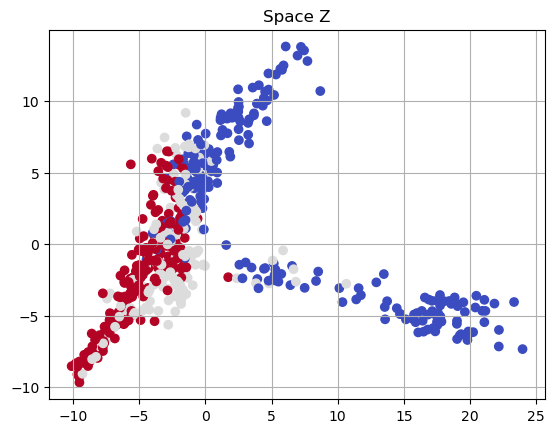

In [20]:
from sklearn.decomposition import PCA

Z = latent.Z_train.copy()
Y = latent.y_train.argmax(axis=1).copy()
Z = PCA().fit_transform(Z)

plt.scatter(Z[:,0], Z[:,1], c=Y, cmap='coolwarm')
plt.grid()
plt.title('Space Z')

# Feature importance

In [21]:
latent.explain_linear(class_label=0, num_k=2)

Training Logistic Regression surrogate.
LR surrogate score: 0.9032


In [26]:
fimp = latent.get_feature_importance(X_test, Y_test_bb, class_label=0, num_k=2)

In [27]:
fimp = [sorted([(f, ex[i]) for i, f in enumerate(feature_names)], key=lambda x: abs(x[1]), reverse=True) if ex is not None else None
        for ex in fimp]

In [29]:
fimp[0][:10]

[('EGFR', np.float64(0.34434280747448526)),
 ('CHIT1', np.float64(-0.24989484339256154)),
 ('PYHIN1', np.float64(0.2290058913069977)),
 ('IFNG', np.float64(0.2198494316881191)),
 ('CASQ2', np.float64(-0.21236509402419695)),
 ('UGT2B15', np.float64(-0.21113083820778386)),
 ('FOSL1', np.float64(0.2018371617901503)),
 ('EMCN', np.float64(-0.19230843386608817)),
 ('CD8B', np.float64(-0.18960955458916046)),
 ('OR6N2', np.float64(0.18597092102471185))]

# Decision Rules +  Pairwise Lift

In [30]:
latent.explain_dectree(class_label=0, num_k=2)

Training Decision Tree surrogate.
DT surrogate score: 0.8966


##### Factual rules

In [31]:
rules = latent.get_decision_rules(X_test, Y_test_bb, class_label=0, num_k=2)

In [32]:
rules = [[(feature_names[int(att[1:])], op, val)
          for (att, op), val in inverse_transform_rule_complete(
              ex, train_data['scaler'], latent.idx_num).items()] if ex is not None else None
         for ex in rules]

In [33]:
rules[0]

[('UGT2B15', '<=', np.float64(-0.24816792397793175)),
 ('CHIT1', '>', np.float64(-0.343084193439576)),
 ('IFNG', '>', np.float64(-0.15612480573984017)),
 ('ZNF750', '<=', np.float64(1.3123736479885268))]

In [36]:
from collections import Counter
from itertools import combinations

univ_counter = Counter()
biv_counter = Counter()
for rule in rules:
    geneset = set([g[0] for g in rule])
    univ_counter.update(geneset)
    biv_counter.update(map(frozenset, combinations(geneset, 2)))
   
norm_count = len(rules)
lift = dict()
for genepair in biv_counter.keys():
    p_biv = biv_counter[genepair]
    p_univ = univ_counter[sorted(genepair)[0]]*univ_counter[sorted(genepair)[1]]
    lift[genepair] = p_biv*norm_count/p_univ

In [38]:
lift = sorted(lift.items(), key=lambda x: x[1], reverse=True)

##### CounterRules/CounterExamples

In [41]:
crules, cfs = latent.get_counterfactuals(X_test, Y_test_bb, class_label=0, num_k=2)

In [42]:
crules = [[[(feature_names[int(att[1:])], op, val)
            for (att, op), val in inverse_transform_rule_complete(
                cx, train_data['scaler'], latent.idx_num).items()] for cx in cx_list]
          if cx_list is not None else None
          for cx_list in crules]

In [43]:
crules[0]

[[('UGT2B15', '<=', np.float64(0.6189293438377228)),
  ('MYL1', '<=', np.float64(0.2895808362525341))]]

In [44]:
cfs = [train_data['scaler'].inverse_transform(cf[:, latent.idx_num])
       if cf is not None and len(cf) else None for cf in cfs]